# Customer Churn Analytics Platform
## 05 — Exploratory Data Analysis (EDA)

**Objective:**  
Explore customer behavior, churn patterns, revenue impact, and risk characteristics to identify meaningful business relationships and potential churn drivers.

### Analysis Goals
- Analyze overall churn distribution
- Compare churn across customer segments
- Investigate tenure and contract behavior
- Analyze the relationship between charges and churn
- Evaluate payment method and service behavior
- Analyze revenue impact of churn
- Explore customer risk categories
- Identify important churn drivers
- Generate business-oriented insights
- Prepare findings for downstream analysis and visualization

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# ============================================================
# Visualization Theme
# ============================================================

plt.style.use("dark_background")

sns.set_theme(
    style="darkgrid",
    context="notebook"
)

DARK_BG = "#0F172A"
CARD_BG = "#1E293B"
TEXT_COLOR = "#F8FAFC"
GRID_COLOR = "#334155"

plt.rcParams.update({
    "figure.facecolor": DARK_BG,
    "axes.facecolor": CARD_BG,
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "grid.color": GRID_COLOR,
    "text.color": TEXT_COLOR,
    "figure.titlesize": 16,
    "axes.titlesize": 14,
    "axes.labelsize": 11
})

print("Visualization theme configured.")

Visualization theme configured.


In [3]:
# ============================================================
# Load Feature Dataset
# ============================================================

DATA_PATH = Path("../data/processed/customer_churn_features.csv")

df = pd.read_csv(DATA_PATH)

print("Feature-engineered dataset loaded successfully.")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

Feature-engineered dataset loaded successfully.
Rows    : 7,043
Columns : 37


In [4]:
# ============================================================
# Initial Validation
# ============================================================

print("Missing values :", df.isna().sum().sum())
print("Duplicate rows :", df.duplicated().sum())
print("Unique customers:", df["customerid"].nunique())

Missing values : 0
Duplicate rows : 0
Unique customers: 7043


In [ ]:
# ============================================================
# Dataset Overview
# ============================================================

df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn,churn_flag,active_flag,seniorcitizen_label,tenure_group,monthly_charges_group,total_charges_group,has_internet,service_count,has_streaming,security_support_count,payment_group,customer_lifetime_value,revenue_per_tenure,monthly_revenue_at_risk,risk_score,risk_category
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,no,0,1,Non-Senior,0-12 Months,Low,Low,1,1,0,1,Electronic Check,29.85,29.850000,29.85,70,High Risk
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,no,0,1,Non-Senior,25-48 Months,Medium,Medium,1,3,0,2,Mailed Check,1889.50,55.573529,56.95,0,Low Risk
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,yes,1,0,Non-Senior,0-12 Months,Medium,Low,1,3,0,2,Mailed Check,108.15,54.075000,0.00,50,Medium Risk
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,no,0,1,Non-Senior,25-48 Months,Medium,Medium,1,3,0,3,Automatic Payment,1840.75,40.905556,42.30,0,Low Risk
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,yes,1,0,Non-Senior,0-12 Months,High,Low,1,1,0,0,Electronic Check,151.65,75.825000,0.00,80,Critical Risk


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
seniorcitizen,7043.0,0.162147,0.368612,0.000,0.000000,0.0000,0.000000,1.00
tenure,7043.0,32.371149,24.559481,0.000,9.000000,29.0000,55.000000,72.00
monthlycharges,7043.0,64.761692,30.090047,18.250,35.500000,70.3500,89.850000,118.75
totalcharges,7043.0,2279.734304,2266.794470,0.000,398.550000,1394.5500,3786.600000,8684.80
churn_flag,7043.0,0.265370,0.441561,0.000,0.000000,0.0000,1.000000,1.00
active_flag,7043.0,0.734630,0.441561,0.000,0.000000,1.0000,1.000000,1.00
has_internet,7043.0,0.783331,0.412004,0.000,1.000000,1.0000,1.000000,1.00
service_count,7043.0,2.941076,1.843899,0.000,1.000000,3.0000,4.000000,7.00
has_streaming,7043.0,0.496805,0.500025,0.000,0.000000,0.0000,1.000000,1.00
security_support_count,7043.0,1.265654,1.286879,0.000,0.000000,1.0000,2.000000,4.00


In [7]:
# ============================================================
# Churn Distribution
# ============================================================

churn_counts = df["churn"].value_counts()

churn_counts

churn
no     5174
yes    1869
Name: count, dtype: int64

In [8]:
# Churn Rate %

churn_rate = (
    df["churn_flag"].mean() * 100
)

print(f"Overall Churn Rate: {churn_rate:.2f}%")

Overall Churn Rate: 26.54%


C:\Users\Kunde\AppData\Local\Temp\ipykernel_15740\671578523.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([


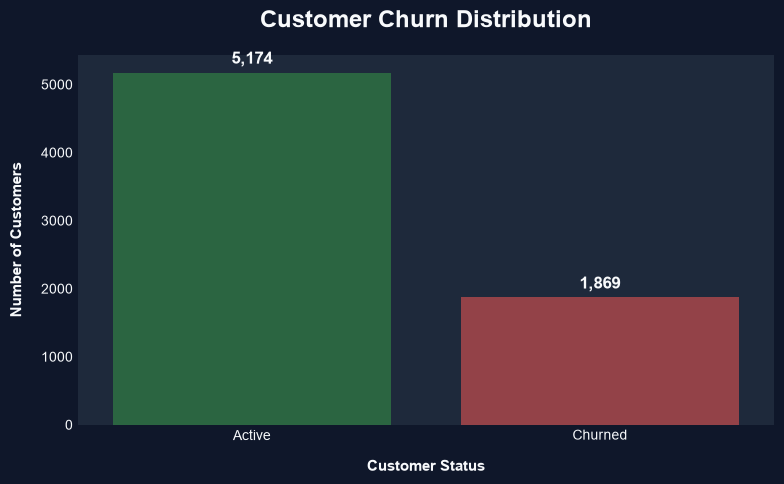

In [ ]:
# ============================================================
# USTOMER CHURN DISTRIBUTION
# Professional Portfolio Visualization
# ============================================================

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="churn",
    hue="churn",
    palette={
        "no": "#216F3F",
        "yes": "#A1343C"
    },
    legend=False,
    edgecolor="none",
    linewidth=0
)

ax.set_title(
    "Customer Churn Distribution",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Customer Status",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Number of Customers",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_xticklabels([
    "Active",
    "Churned"
])

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

# Add customer counts
for bar in ax.patches:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 80,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# Churn by Contract
# ============================================================

contract_churn = pd.crosstab(
    df["contract"],
    df["churn"]
)

contract_churn

churn,no,yes
contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


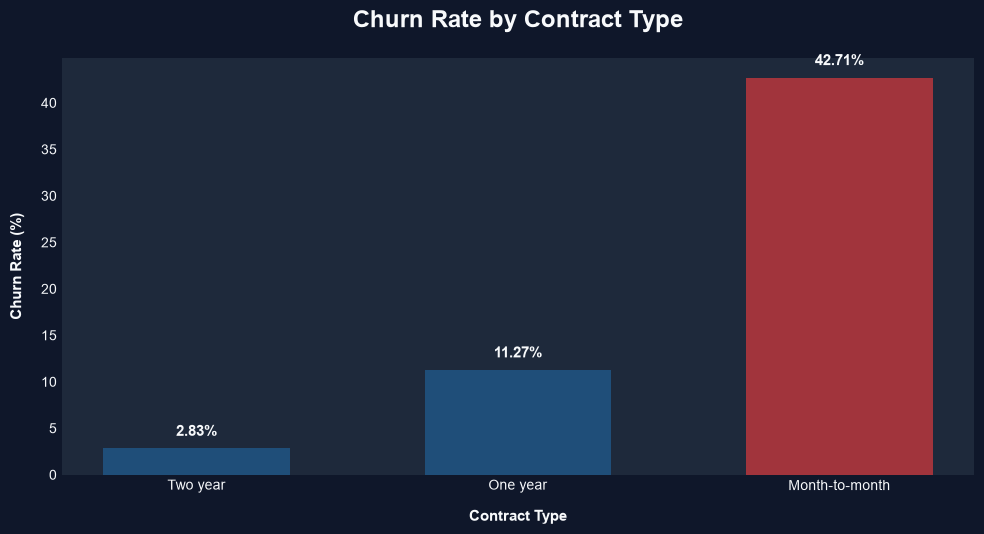

In [11]:
# ============================================================
# CELL — CONTRACT CHURN ANALYSIS
# Professional Portfolio Visualization
# ============================================================

contract_churn = (
    df.groupby("contract")
      .agg(
          Customers=("customerid", "count"),
          Churned=("churn", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

contract_churn["Churn_Rate"] = (
    contract_churn["Churned"]
    / contract_churn["Customers"]
    * 100
)

# Clean display labels
contract_churn["Contract_Display"] = (
    contract_churn["contract"]
    .astype(str)
    .str.strip()
    .replace({
        "month-to-month": "Month-to-Month",
        "one year": "One Year",
        "two year": "Two Year"
    })
)

# Sort from lowest to highest churn
contract_churn = contract_churn.sort_values(
    "Churn_Rate",
    ascending=True
)

# Highlight highest churn
max_index = contract_churn["Churn_Rate"].idxmax()

bar_colors = [
    "#A1343C" if index == max_index else "#1F4E79"
    for index in contract_churn.index
]

plt.figure(figsize=(10, 5.5))

ax = plt.gca()

bars = ax.bar(
    contract_churn["Contract_Display"],
    contract_churn["Churn_Rate"],
    color=bar_colors,
    edgecolor="none",
    width=0.58
)

ax.set_title(
    "Churn Rate by Contract Type",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Contract Type",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

# Add percentages above bars
for bar, rate in zip(
    bars,
    contract_churn["Churn_Rate"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Business Question

> Which contract type has the highest churn volume?

### Insight

The **Month-to-Month contract** has the highest churn volume by a significant margin, with substantially more churned customers than One-Year and Two-Year contracts.

This indicates that customers on short-term contracts represent the largest source of customer churn and should be a primary focus of retention strategies.

**Business implication:**  
The company should consider targeted retention offers, contract upgrade incentives, and loyalty benefits to encourage Month-to-Month customers to move toward longer-term contracts.

In [12]:
# ============================================================
# Churn by Tenure Group
# ============================================================

tenure_churn = pd.crosstab(
    df["tenure_group"],
    df["churn"]
)

tenure_churn


churn,no,yes
tenure_group,,
0-12 Months,1149,1037
13-24 Months,730,294
25-48 Months,1269,325
49-72 Months,2026,213


In [18]:
# ============================================================
# CREATE TENURE GROUP
# ============================================================

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0–12 Months",
        "13–24 Months",
        "25–48 Months",
        "49–72 Months"
    ],
    right=True
)

print(df["tenure_group"].value_counts(sort=False))

tenure_group
0–12 Months     2186
13–24 Months    1024
25–48 Months    1594
49–72 Months    2239
Name: count, dtype: int64


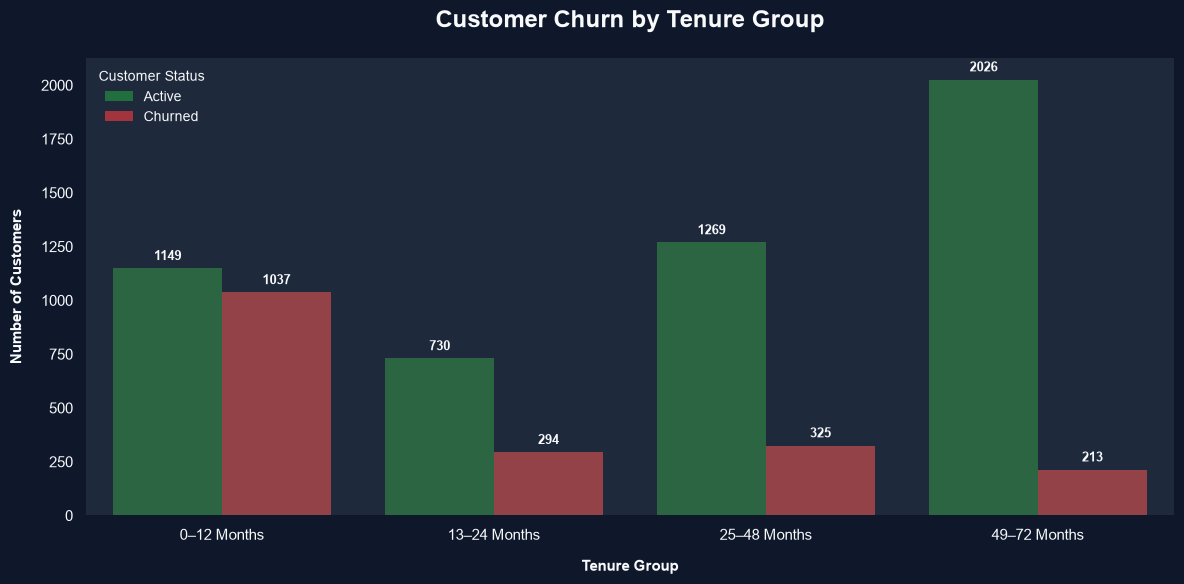

In [22]:
# ============================================================
# CELL — CUSTOMER CHURN BY TENURE GROUP
# Professional Portfolio Visualization
# ============================================================
from matplotlib.patches import Patch

tenure_churn_volume = (
    df.groupby(
        ["tenure_group", "churn"],
        observed=False
    )
    .size()
    .reset_index(name="Customers")
)

tenure_order = [
    "0–12 Months",
    "13–24 Months",
    "25–48 Months",
    "49–72 Months"
]

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=tenure_churn_volume,
    x="tenure_group",
    y="Customers",
    hue="churn",
    order=tenure_order,
    hue_order=["no", "yes"],
    palette={
        "no": "#216F3F",
        "yes": "#A1343C"
    },
    edgecolor="none",
    linewidth=0
)

ax.set_title(
    "Customer Churn by Tenure Group",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Tenure Group",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Number of Customers",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.legend(
    title="Customer Status",
    frameon=False,
    labels=["Active", "Churned"]
)
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)


# ============================================================
# CUSTOM LEGEND
# ============================================================

legend_handles = [
    Patch(
        facecolor="#216F3F",
        edgecolor="none",
        label="Active"
    ),
    Patch(
        facecolor="#A1343C",
        edgecolor="none",
        label="Churned"
    )
]

ax.legend(
    handles=legend_handles,
    title="Customer Status",
    frameon=False,
    loc="upper left",
    fontsize=10,
    title_fontsize=10
)

# Add values
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=4,
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CHURN RATE BY TENURE GROUP
# ============================================================

tenure_rate = (
    df.groupby(
        "tenure_group",
        observed=False
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

tenure_rate["Churn_Rate"] *= 100

tenure_rate = tenure_rate.reindex(tenure_order)

tenure_rate

,Customers,Churned_Customers,Churn_Rate
tenure_group,,,
0–12 Months,2186,1037,47.438243
13–24 Months,1024,294,28.710938
25–48 Months,1594,325,20.388959
49–72 Months,2239,213,9.513176


### Business Insight:

Customers in their first 12 months show the highest churn rate at 47.44%.
Churn declines consistently as tenure increases, reaching only 9.51%
among customers with 49–72 months of tenure.

This indicates that the early customer lifecycle is a critical retention
period and should be prioritized for onboarding, engagement, and retention
initiatives.

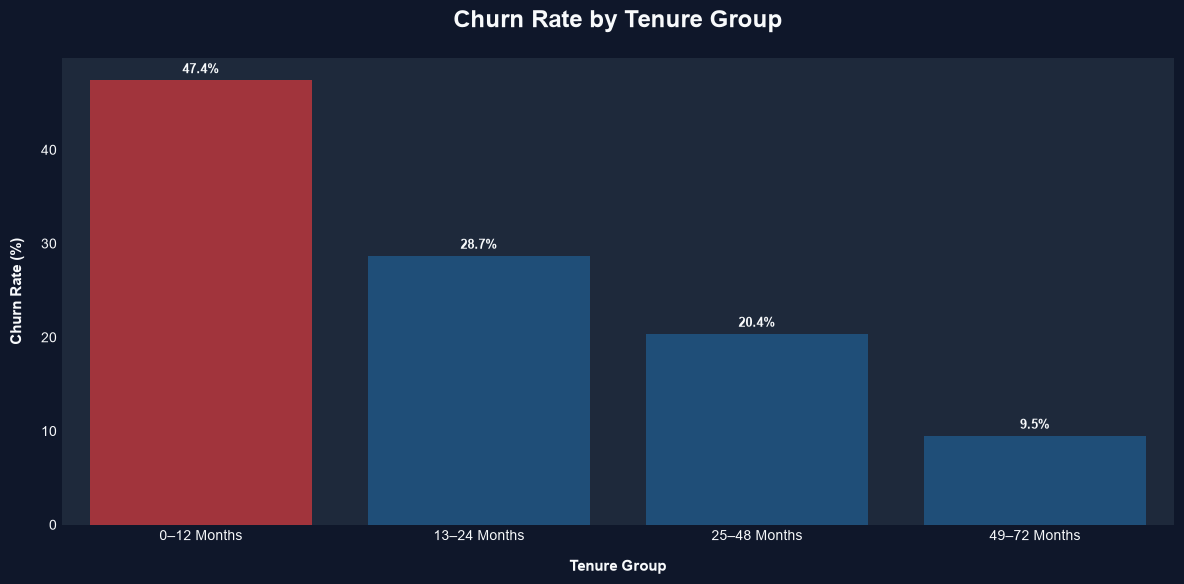

In [27]:
# ============================================================
# CELL 14 — CHURN RATE BY TENURE GROUP
# Professional Portfolio Visualization
# ============================================================

tenure_rate_plot = tenure_rate.reset_index()

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=tenure_rate_plot,
    x="tenure_group",
    y="Churn_Rate",
    order=tenure_order,
    color="#1F4E78",
    edgecolor="none"
)

# Highlight the highest churn-rate bar
max_index = tenure_rate_plot["Churn_Rate"].idxmax()

for i, bar in enumerate(ax.patches):
    if i == list(tenure_rate_plot.index).index(max_index):
        bar.set_facecolor("#A1343C")
    else:
        bar.set_facecolor("#1F4E78")

ax.set_title(
    "Churn Rate by Tenure Group",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Tenure Group",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

# Add percentage labels
ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3,
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [28]:
highest_tenure_churn_group = tenure_rate["Churn_Rate"].idxmax()
highest_tenure_churn_rate = tenure_rate["Churn_Rate"].max()

lowest_tenure_churn_group = tenure_rate["Churn_Rate"].idxmin()
lowest_tenure_churn_rate = tenure_rate["Churn_Rate"].min()

print("BUSINESS INSIGHT")
print("-" * 50)

print(
    f"Highest churn rate: "
    f"{highest_tenure_churn_group} "
    f"({highest_tenure_churn_rate:.2f}%)"
)

print(
    f"Lowest churn rate: "
    f"{lowest_tenure_churn_group} "
    f"({lowest_tenure_churn_rate:.2f}%)"
)

BUSINESS INSIGHT
--------------------------------------------------
Highest churn rate: 0–12 Months (47.44%)
Lowest churn rate: 49–72 Months (9.51%)


In [ ]:
# ============================================================
# CUSTOMER CHURN BY MONTHLY CHARGES
# ============================================================

monthly_charges_churn = (
    df.groupby(
        ["monthly_charges_group", "churn"],
        observed=False
    )
    .size()
    .reset_index(name="Customers")
)

monthly_charge_order = [
    "Low",
    "Medium",
    "High",
    "Very High"
]

monthly_charges_churn

,monthly_charges_group,churn,Customers
0,High,no,1577
1,High,yes,809
2,Low,no,1491
3,Low,yes,162
4,Medium,no,937
5,Medium,yes,328
6,Very High,no,1169
7,Very High,yes,570


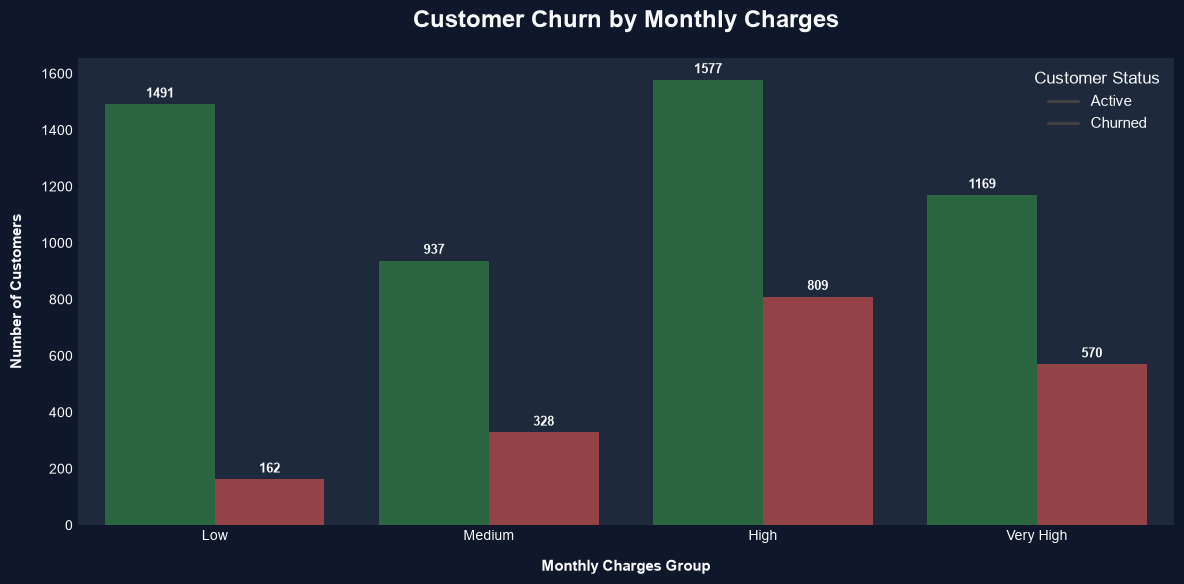

In [ ]:
# ============================================================
# CUSTOMER CHURN BY MONTHLY CHARGES
# Professional Portfolio Visualization
# ============================================================

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=monthly_charges_churn,
    x="monthly_charges_group",
    y="Customers",
    hue="churn",
    order=monthly_charge_order,
    hue_order=["no", "yes"],
    palette={
        "no": "#216F3F",
        "yes": "#A1343C"
    },
    edgecolor="none"
)

ax.set_title(
    "Customer Churn by Monthly Charges",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Monthly Charges Group",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Number of Customers",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.legend(
    title="Customer Status",
    labels=["Active", "Churned"],
    frameon=False
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3,
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

### Business Insight

Higher monthly charges may be associated with increased churn, particularly if customers perceive insufficient value relative to their monthly cost. 

In [31]:
# ============================================================
# CHURN RATE BY MONTHLY CHARGES
# ============================================================

charges_rate = (
    df.groupby(
        "monthly_charges_group",
        observed=False
    )["churn_flag"]
    .agg(
        Customers="count",
        Churned_Customers="sum",
        Churn_Rate="mean"
    )
)

charges_rate["Churn_Rate"] *= 100

charges_rate = charges_rate.reindex(monthly_charge_order)

charges_rate

,Customers,Churned_Customers,Churn_Rate
monthly_charges_group,,,
Low,1653,162,9.800363
Medium,1265,328,25.928854
High,2386,809,33.906119
Very High,1739,570,32.777458


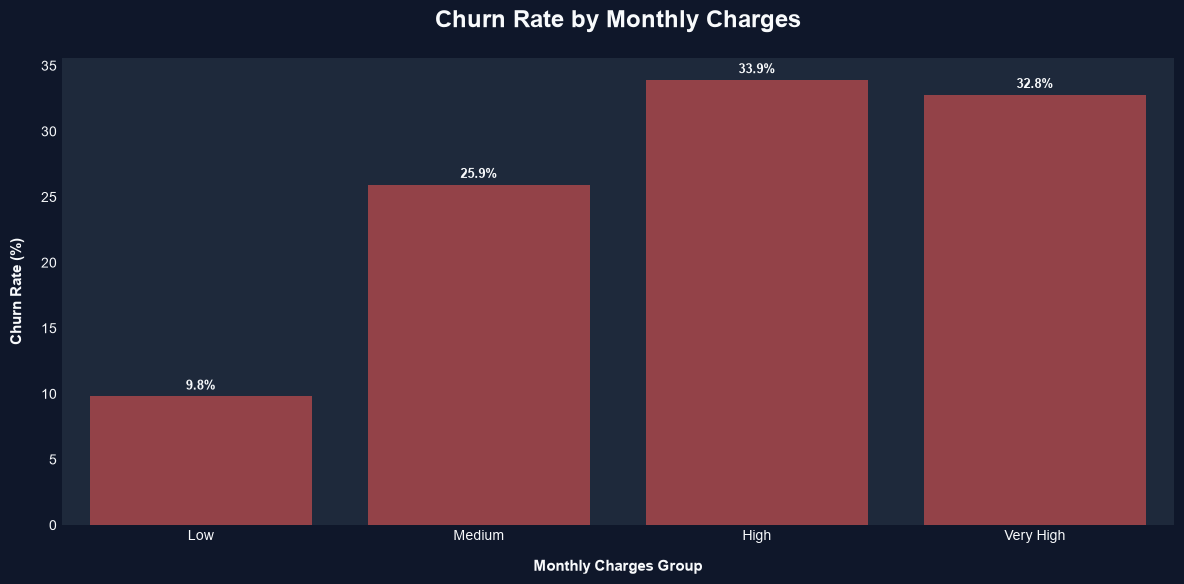

In [33]:
# ============================================================
# CHURN RATE BY MONTHLY CHARGES
# Professional Portfolio Visualization
# ============================================================

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=charges_rate.reset_index(),
    x="monthly_charges_group",
    y="Churn_Rate",
    order=monthly_charge_order,
    color="#A1343C",
    edgecolor="none"
)

ax.set_title(
    "Churn Rate by Monthly Charges",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Monthly Charges Group",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3,
    fontsize=9,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [36]:
# Business Insight: 

highest_charge_group = charges_rate["Churn_Rate"].idxmax()
highest_charge_rate = charges_rate["Churn_Rate"].max()

print(
    f"Business Insight : Highest churn rate occurs in the "
    f"{highest_charge_group} monthly-charge segment: "
    f"{highest_charge_rate:.2f}%."
)

Business Insight : Highest churn rate occurs in the High monthly-charge segment: 33.91%.
